# Final evaluation: claim frequency per policy

**The problem.** A motor insurer needs to estimate how many claims to expect per 100 policy-years across different vehicle, driver and region profiles, and the coverage duration ranges from a few days to more than a year. **Why calibration by segment matters.** A model can get the total right and still be systematically wrong in specific groups, for example in very short coverages; a small aggregate error can hide large deviations of opposite signs across segments. **The question.** On the French `freMTPL2freq` benchmark, does the Poisson with a fixed exposure offset, frozen on the training data, outperform the global reference rate on held-out records never used before, and where do predicted rates depart from observed rates by exposure band, vehicle age and region?

This notebook presents the single final evaluation of the **test** partition, run once by `python -m freq_sinistros stage5` after integrity checks. Each section follows the sequence question → execution → insights. Conclusions are restricted to the benchmark. `production_eligible` remains false.

In [1]:
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("retina")
import pandas as pd
from IPython.display import display

from freq_sinistros import artifacts, plots

LANG = "en_us"
ROOT = artifacts.project_root()
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 30
out5 = artifacts.load_stage5(ROOT)

## 1. Origin and integrity

**Question.** Did the evaluation use the approved model, script and code, with the expected test population, and are the aggregates shown those of the official run?

In [2]:
display(pd.Series(artifacts.verify_stage5(ROOT)["checks"], name="ok"))
display(artifacts.gate_checks(out5))
display(artifacts.run_summary(out5))

status_completed               True
files_match_checksums          True
frozen_model_matches_record    True
script_matches_record          True
integrity_gate_ok              True
test_rows_match_stage2         True
reconciliation_ok              True
single_official_run_lock       True
Name: ok, dtype: bool

arff_sha256                             True
assignments_sha256                      True
code_modules_match_frozen               True
frozen_model_sha256_approved            True
module_arff_approved                    True
module_freeze_approved                  True
module_profiles_approved                True
partition_config_sha256                 True
production_eligible_false               True
protocol_config_sha256                  True
stage3_coefficients_sha256              True
stage3_comparison_config_sha256         True
stage3_intervals_sha256                 True
stage3_preprocessing_sha256             True
stage3_protocol_amendment_sha256        True
stage3_validation_metrics_sha256        True
stage5_script_sha256_approved           True
verify_freeze_code_modules_unchanged    True
verify_freeze_exit_0                    True
verify_freeze_ok                        True
Name: ok, dtype: bool

status                                                                   completed
test_rows                                                                   101859
policy_years                                                           53,839.0932
observed_claims                                                         5,415.0000
observed_zeros                                                               96726
wall_s                                                                     88.4740
peak_rss_mib                                                              236.4000
bootstrap_replicas                                                            1000
bootstrap_seed                                                            20261121
frozen_model_sha256_approved     8ac94b7e59e55becdd0319f05f9d958483ea4042dc0aba...
stage5_script_sha256_approved    c0365ad5566e32e5099c48bb1d007367e646ce63ee8b04...
test_ids_sha256                  11808b8102160e12da25942da6ae0d841919600d64a1a7...
dtyp

### Insights

The integrity gate was satisfied before the test rows were made available to the evaluator (the prior freeze check uses the whole-ARFF reader but returns only the validation partition): the SHA-256 of the frozen model and of the script match the approved values, the ARFF, the assignments and the source files match the model, and the code modules match those recorded. The official run evaluated 101,859 test records (53,839.09 policy-years, 5,415 claims and 96,726 zeros), in a single run protected by a lock, created after the gate and before the test rows were made available; the row count checked refers to the rows made available to the evaluator, not to the physical reading of the ARFF. The aggregates are verified here without rereading the ARFF, and no test row is persisted.

## 2. Primary comparison

**Question.** Does the frozen Poisson have a lower mean Poisson deviance than the global rate on the same test rows, with original counts and exposures? The paired Poisson − global rate difference uses 1,000 bootstrap replicates by `IDpol` (seed 20261121) and, as a sensitivity, by profile key.

,candidate,records,exposure,observed claims,predicted claims,observed_rate_per_100,predicted_rate_per_100,predicted − observed rate,mean Poisson deviance,mean log-likelihood
0,poisson,101859,"53,839.0932",5415,"5,442.1495",10.0577,10.1082,0.0504,0.3190,-0.2107
1,global,101859,"53,839.0932",5415,"5,429.3637",10.0577,10.0844,0.0267,0.3308,-0.2166


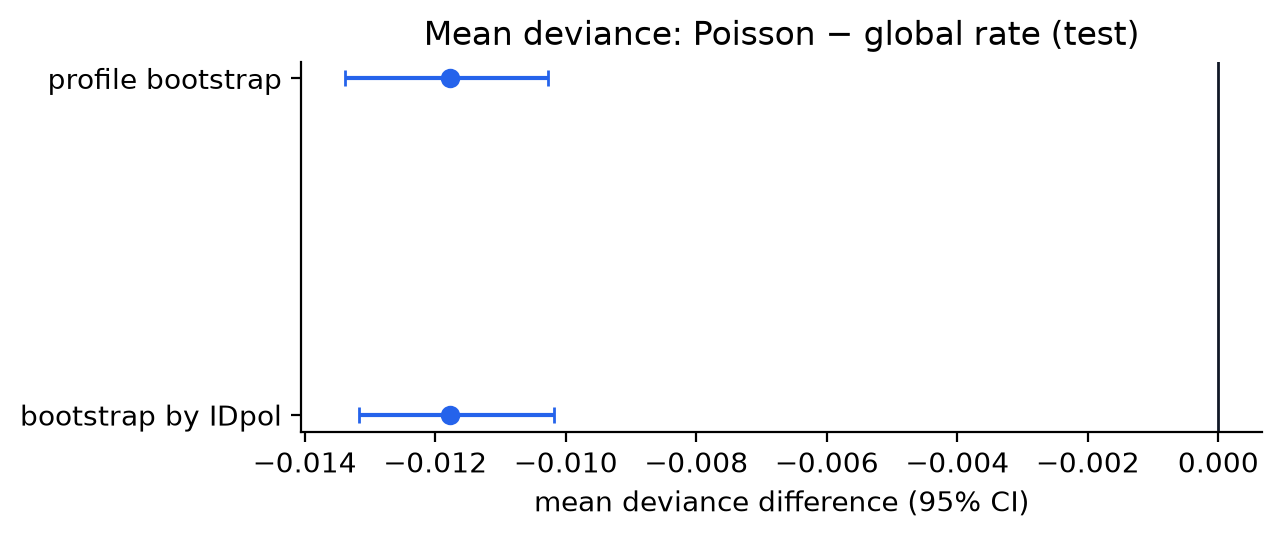

In [3]:
display(artifacts.metrics_view(out5, LANG))
plots.show(plots.plot_paired_difference(out5["test_intervals"], LANG))

### Insights

The mean deviance is 0.31902 for Poisson and 0.33079 for the global rate. The paired difference is -0.01177 (95% CI -0.01317 to -0.01018; negative values favor Poisson), and the profile bootstrap gives -0.01338 to -0.01028. Both intervals lie entirely below zero, so the test supports a gain of Poisson over the global rate on the primary metric. The intervals are conditional on the fitted models and do not include the variability of the fit. Overall, the observed rate is 10.058 per 100 policy-years; the predicted rate is 10.108 (Poisson) and 10.084 (global rate), with differences of 0.050 and 0.027. Each 95% interval refers to the predicted − observed difference of one candidate: -0.233 to 0.317 for Poisson and -0.253 to 0.288 for the global rate, and both include zero. These individual intervals do not test equivalence between the candidates nor compare their absolute errors, whose point values are 0.050 (Poisson) and 0.027 (global rate). The confirmed gain is in the mean deviance.

## 3. Calibration by exposure band

**Question.** How do predicted rates compare with observed rates by exposure band, and does the behavior observed in validation repeat on the test? Differences are predicted − observed, per 100 policy-years, computed with the total exposure of each band and direct predictions; the `(0; 0.02]` band stays visible and segments with fewer than 500 records or 25 policy-years are flagged.

,segment,records,policy-years,observed claims,predicted claims,observed rate per 100,predicted rate per 100,predicted − observed,CI low,CI high,low support
0,"(0, 0.02]",2921,32.0932,82,4.5065,255.5058,14.0418,-241.4641,-296.6559,-190.3120,False
1,"(0.02, 0.08]",14341,916.9000,365,113.7112,39.8080,12.4017,-27.4063,-31.5899,-23.3945,False
2,"(0.08, 0.25]",16168,"2,788.5800",603,335.8947,21.6239,12.0454,-9.5785,-11.3882,-7.9628,False
3,"(0.25, 0.50]",19859,"7,789.0700",1012,888.4094,12.9926,11.4058,-1.5867,-2.4217,-0.7464,False
4,"(0.50, 0.75]",13877,"8,791.4200",952,"1,002.5454",10.8287,11.4037,0.5749,-0.1218,1.3333,False
5,"(0.75, 1)",9300,"8,108.0300",671,884.3093,8.2757,10.9066,2.6308,1.9811,3.2746,False
6,= 1,25222,"25,222.0000",1712,"2,191.1626",6.7877,8.6875,1.8998,1.5455,2.2113,False
7,> 1,171,191.0000,18,21.6106,9.4241,11.3144,1.8904,NaN,NaN,True


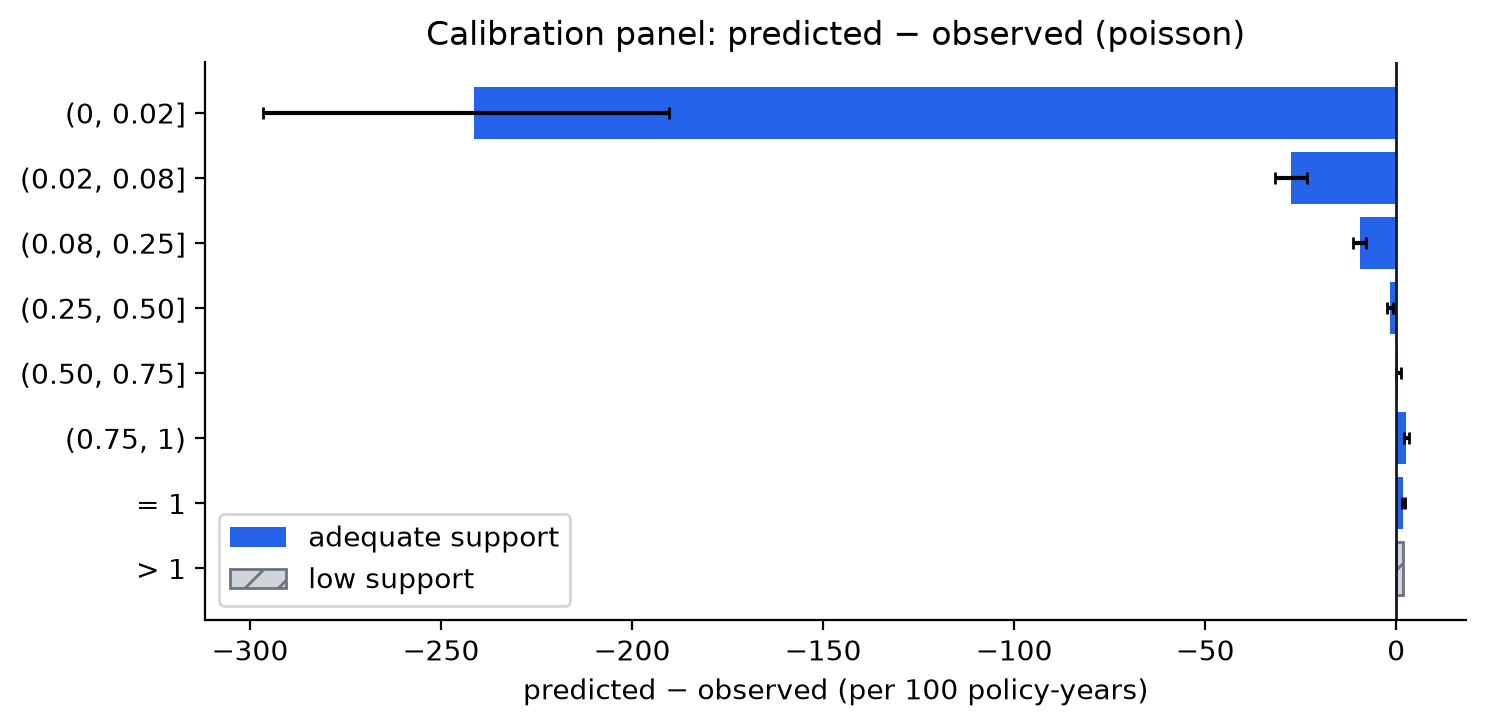

,band,test_rows,test_observed_rate,test_predicted_rate,test_diff,test_ci_low,test_ci_high,test_low_support,validation_diff,same_sign,validation_diff_inside_test_ci
0,"(0, 0.02]",2921,255.5058,14.0418,-241.4641,-296.6559,-190.3120,False,-224.7565,True,True
1,"(0.02, 0.08]",14341,39.8080,12.4017,-27.4063,-31.5899,-23.3945,False,-23.7700,True,True
2,"(0.08, 0.25]",16168,21.6239,12.0454,-9.5785,-11.3882,-7.9628,False,-11.6193,True,False
3,"(0.25, 0.50]",19859,12.9926,11.4058,-1.5867,-2.4217,-0.7464,False,-0.9274,True,True
4,"(0.50, 0.75]",13877,10.8287,11.4037,0.5749,-0.1218,1.3333,False,1.3324,True,True
5,"(0.75, 1)",9300,8.2757,10.9066,2.6308,1.9811,3.2746,False,1.6639,True,False
6,= 1,25222,6.7877,8.6875,1.8998,1.5455,2.2113,False,1.7946,True,True
7,> 1,171,9.4241,11.3144,1.8904,NaN,NaN,True,8.4641,True,False


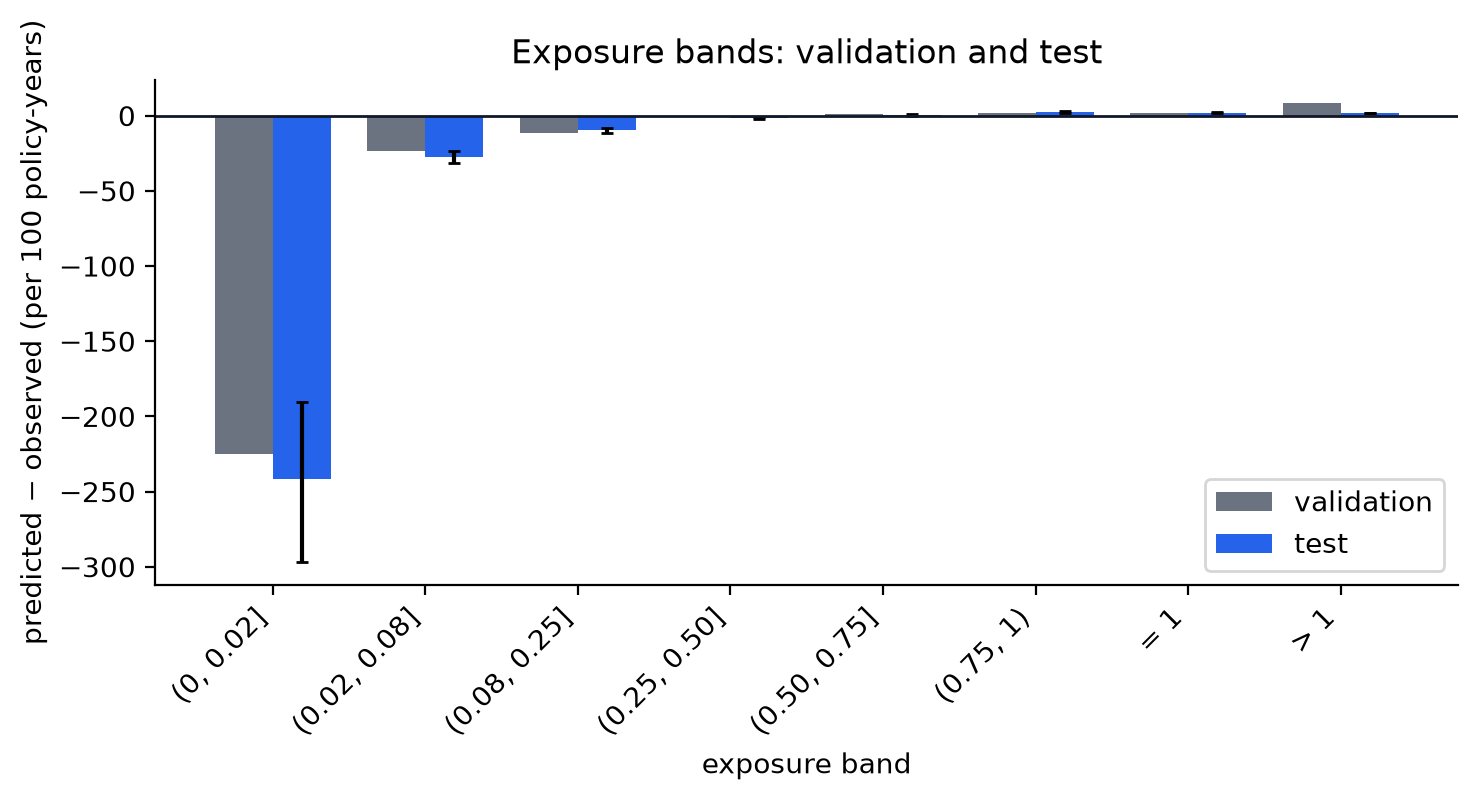

In [4]:
display(artifacts.panel_view(out5, "exposure_band", "poisson", LANG))
plots.show(plots.plot_panel(out5["panel"], LANG, "exposure_band"))
display(out5["validation_vs_test_bands"])
plots.show(plots.plot_validation_vs_test(out5["validation_vs_test_bands"],
                                         LANG))

### Insights

The bias in short exposures persists on the test. In `(0; 0.02]`, the observed rate is 255.51 per 100 policy-years and the Poisson-predicted rate is 14.04, a difference of -241.5 (CI -296.7 to -190.3); in validation, the difference was -224.8. At exactly one year, the observed rate is 6.79 and the predicted rate 8.69 (difference 1.90). The sign of the difference matches that of validation in 8 of 8 bands, and the validation difference falls inside the test interval in 5 of them; the bands `(0.08, 0.25]`, `(0.75, 1)` have the validation difference outside the test interval. The fixed offset, therefore, underestimates very short exposures and overestimates long ones on the test as well, and this is a limit of the selected model, which was not recalibrated.

## 4. Calibration by vehicle age and region

**Question.** Are there deviations by vehicle age or region that the intervals distinguish from zero? Low-support segments are shown without an interval.

,segment,records,policy-years,observed claims,predicted claims,observed rate per 100,predicted rate per 100,predicted − observed,CI low,CI high,low support
0,0-1,19397,"7,517.4532",1233,"1,246.8921",16.4018,16.5866,0.1848,-0.7228,1.0705,False
1,11-20,26609,"15,462.0896",1179,"1,251.4327",7.6251,8.0936,0.4685,0.0130,0.8822,False
2,2-5,28885,"15,258.3124",1437,"1,426.5169",9.4178,9.3491,-0.0687,-0.5425,0.4394,False
3,21+,1270,779.1884,29,51.4280,3.7218,6.6002,2.8784,1.4026,4.1323,False
4,6-10,25698,"14,822.0495",1537,"1,465.8799",10.3697,9.8899,-0.4798,-1.0227,-0.0137,False


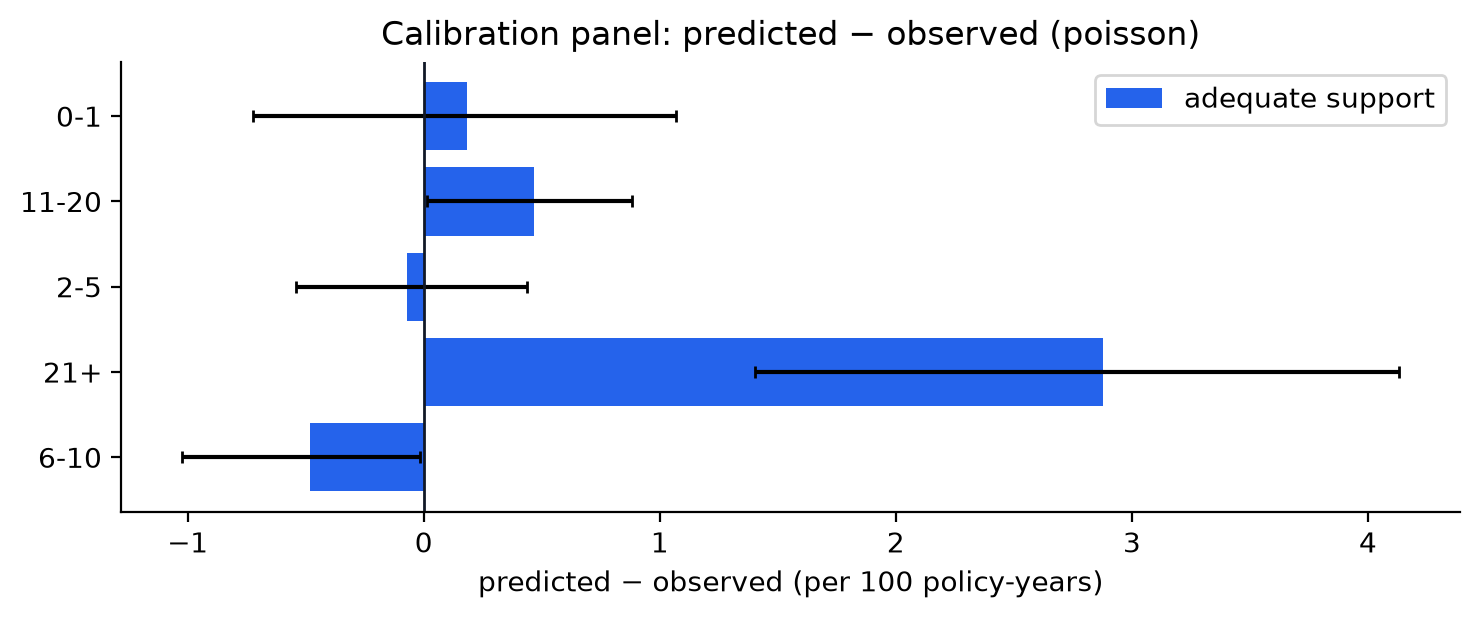

,segment,records,policy-years,observed claims,predicted claims,observed rate per 100,predicted rate per 100,predicted − observed,CI low,CI high,low support
0,R11,10462,"4,506.6061",607,601.0456,13.4691,13.3370,-0.1321,-1.2410,0.9702,False
1,R21,442,173.1374,19,23.0367,10.9739,13.3055,2.3315,NaN,NaN,True
2,R22,1185,559.0584,67,66.8738,11.9844,11.9619,-0.0226,-2.8395,2.8216,False
3,R23,1258,460.4391,45,42.5736,9.7733,9.2463,-0.5270,-3.5475,2.3006,False
4,R24,23983,"15,310.3704",1425,"1,365.9493",9.3074,8.9217,-0.3857,-0.8851,0.0746,False
5,R25,1579,962.0739,91,91.7180,9.4587,9.5334,0.0746,-2.2473,1.9939,False
6,R26,1571,759.1303,70,74.8381,9.2211,9.8584,0.6373,-1.6844,2.8743,False
7,R31,4090,"1,724.0599",168,181.5298,9.7444,10.5292,0.7848,-0.8655,2.2299,False
8,R41,2023,"1,265.1131",109,92.8302,8.6158,7.3377,-1.2781,-2.9260,0.1848,False
9,R42,309,171.2837,17,19.3021,9.9251,11.2691,1.3440,NaN,NaN,True


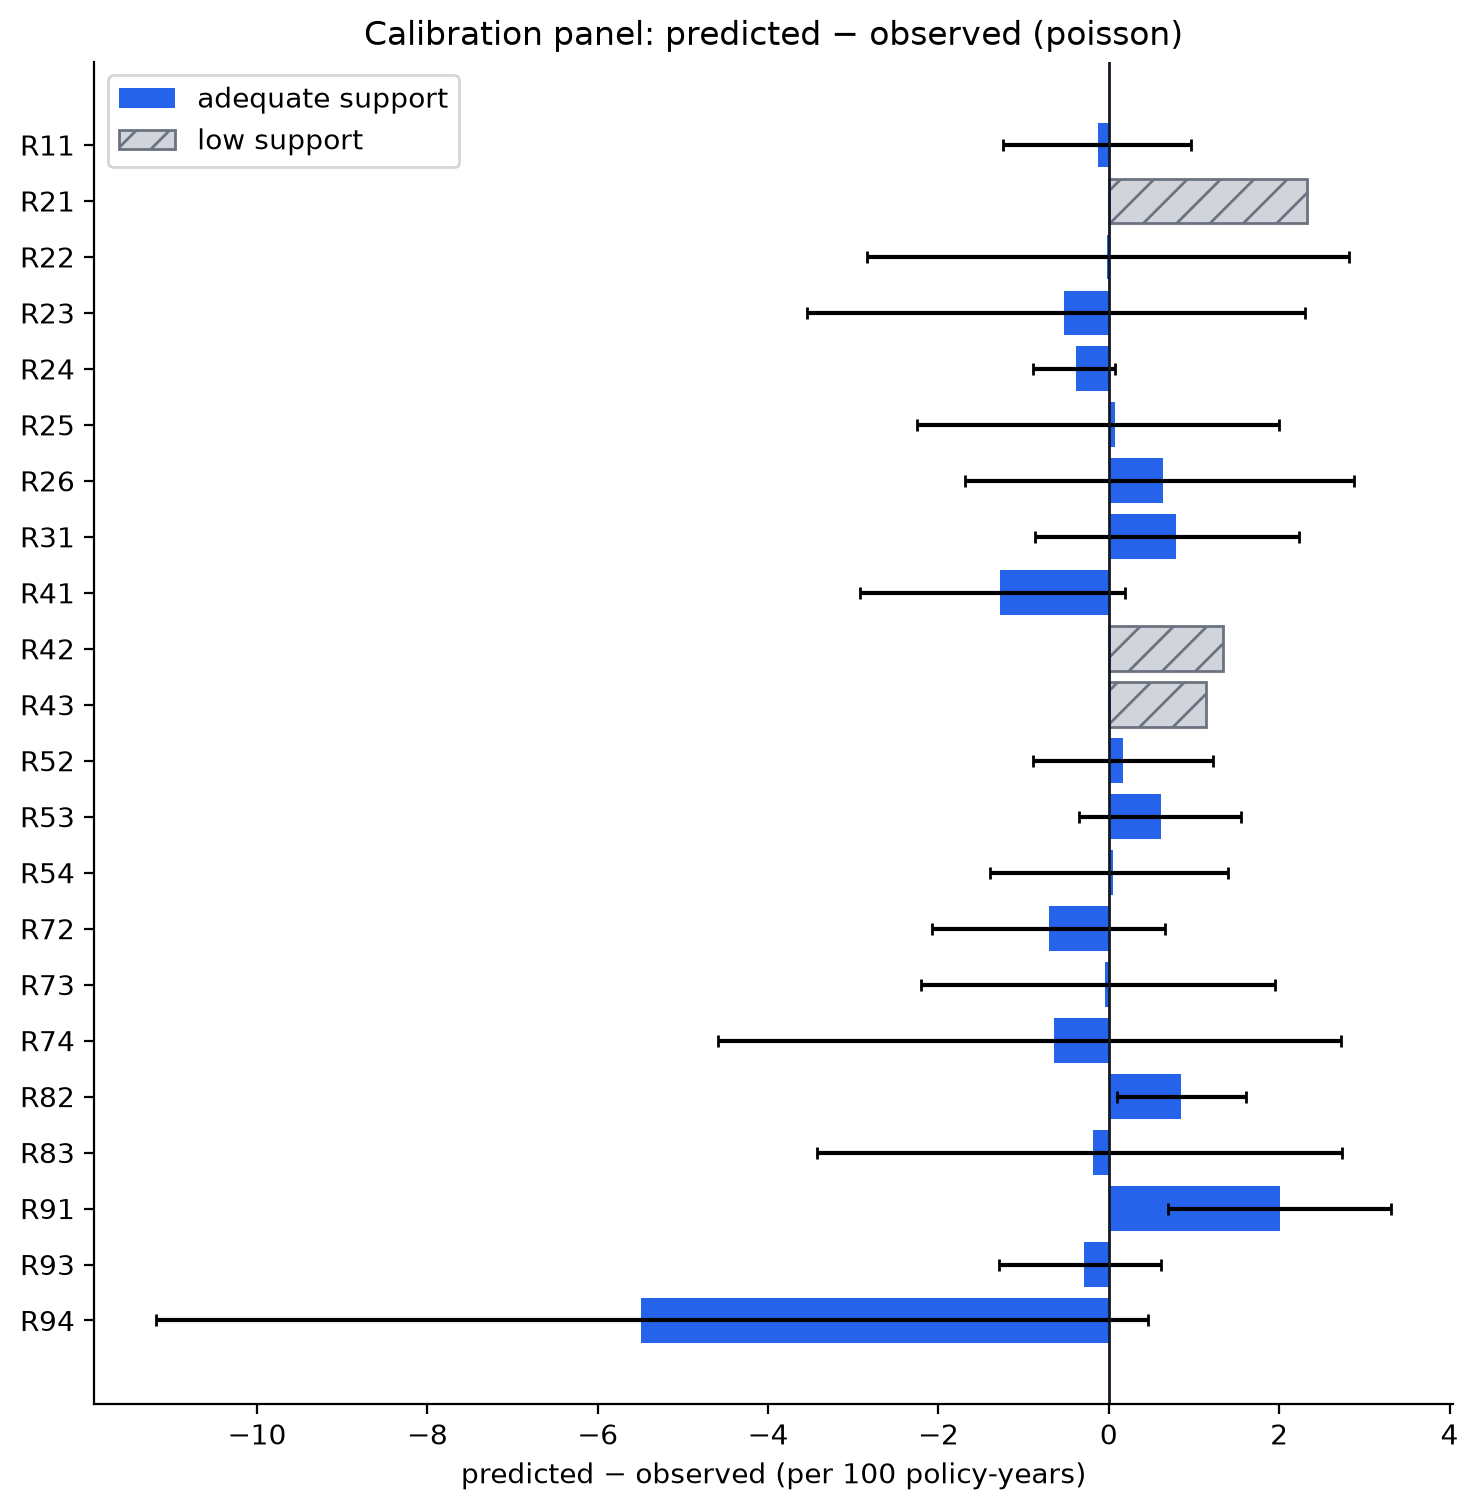

In [5]:
for family in ("vehicle_age", "region"):
    display(artifacts.panel_view(out5, family, "poisson", LANG))
    plots.show(plots.plot_panel(out5["panel"], LANG, family))

### Insights

By vehicle age, the intervals distinguish from zero only the segments `11-20`, `21+`, `6-10`. By region, only `R82`, `R91`; the regions `R21`, `R42`, `R43` have low support and no interval. The remaining segments have intervals that include zero. Since these are many simultaneous comparisons without multiplicity adjustment, these deviations are descriptive and do not by themselves indicate a specification failure.

## 5. Reconciliation

**Question.** Does each segmentation add up records, exposure and observed and predicted counts to the total of each candidate?

In [6]:
display(out5["test_reconciliation"])

,degree,population,candidate,family,indicator,segments_sum,total,ok,direct_sum_check
0,test,test,poisson,exposure_band,rows,"101,859.0000","101,859.0000",True,"101,859.0000"
1,test,test,poisson,exposure_band,exposure,"53,839.0932","53,839.0932",True,"53,839.0932"
2,test,test,poisson,exposure_band,observed_claims,"5,415.0000","5,415.0000",True,"5,415.0000"
3,test,test,poisson,exposure_band,predicted_claims,"5,442.1495","5,442.1495",True,"5,442.1495"
4,test,test,poisson,vehicle_age,rows,"101,859.0000","101,859.0000",True,"101,859.0000"
5,test,test,poisson,vehicle_age,exposure,"53,839.0932","53,839.0932",True,"53,839.0932"
6,test,test,poisson,vehicle_age,observed_claims,"5,415.0000","5,415.0000",True,"5,415.0000"
7,test,test,poisson,vehicle_age,predicted_claims,"5,442.1495","5,442.1495",True,"5,442.1495"
8,test,test,poisson,region,rows,"101,859.0000","101,859.0000",True,"101,859.0000"
9,test,test,poisson,region,exposure,"53,839.0932","53,839.0932",True,"53,839.0932"


### Insights

The 24 checks (two candidates, three segmentations and four indicators) were satisfied: the sum of the segments coincides with the 101,859 records, the 53,839.09 policy-years, the 5,415 observed claims and the predicted claims of each candidate.

## 6. Conclusion and limits

**Question.** What does the test support, and what does it not support?

In [7]:
display(pd.Series(out5["conclusion"]["primary"], name="primary"))
display(pd.Series(out5["conclusion"]["profile_cluster_bootstrap"],
                  name="profile_cluster_bootstrap"))

ci_high                                -0.0102
ci_low                                 -0.0132
d_dev_poisson_minus_global             -0.0118
verdict                       ganho_sustentado
Name: primary, dtype: object

ci_high                                -0.0103
ci_low                                 -0.0134
d_dev_poisson_minus_global             -0.0118
verdict                       ganho_sustentado
Name: profile_cluster_bootstrap, dtype: object

### Insights

The test supports a gain of the fixed-offset Poisson over the global rate in mean Poisson deviance, and the frozen choice is preserved. The confirmed gain is in the mean deviance; it does not remove the systematic bias in short exposures. In total calibration, the point absolute error of Poisson is larger than the reference's, but the individual intervals do not allow concluding either equivalence or a difference between the candidates. The results hold within the French benchmark, with no temporal evidence, without `BonusMalus` (unknown measurement time, Dutang & Charpentier, 2018) and without zero-inflated models; intervals are conditional on the fitted models. The model is not eligible for production.

## References

- Dutang, C., & Charpentier, A. (2018). *CASdatasets: Insurance datasets* (freMTPL2freq). https://dutangc.github.io/CASdatasets/reference/freMTPL.html